In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw, PandasTools

In [2]:
smiles = [
    "CCC1C(=O)N(CC(=O)N(C(C(=O)NC(C(=O)N(C(C(=O)NC(C(=O)NC(C(=O)N(C(C(=O)N(C(C(=O)N(C(C(=O)N(C(C(=O)N1)C(C(C)CC=CC)O)C)C(C)C)C)CC(C)C)C)CC(C)C)C)C)C)CC(C)C)C)C(C)C)CC(C)C)C)C",
    "CN1CCN(CC1)C2=C3C=CC=CC3=NC4=C(N2)C=C(C=C4)C",
    "CC1=C(C(CCC1)(C)C)C=CC(=CC=CC(=CC=CC=C(C)C=CC=C(C)C=CC2=C(CCCC2(C)C)C)C)C",
    "CCCCCC1=CC(=C(C(=C1)O)C2C=C(CCC2C(=C)C)C)O",
]
names = ["cyclosporine", "clozapine", "beta-carotene", "cannabidiol"]

,name,smiles,ROMol
0,cyclosporine,CCC1C(=O)N(CC(=O)N(C(C(=O)NC(C(=O)N(C(C(=O)NC(...,
1,clozapine,CN1CCN(CC1)C2=C3C=CC=CC3=NC4=C(N2)C=C(C=C4)C,
2,beta-carotene,CC1=C(C(CCC1)(C)C)C=CC(=CC=CC(=CC=CC=C(C)C=CC=...,
3,cannabidiol,CCCCCC1=CC(=C(C(=C1)O)C2C=C(CCC2C(=C)C)C)O,

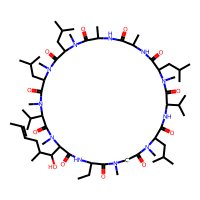
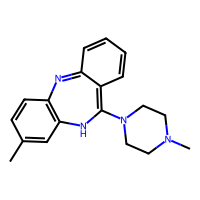
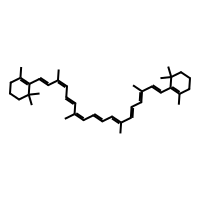
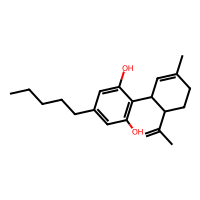

In [3]:
molecules = pd.DataFrame({"name": names, "smiles": smiles})
PandasTools.AddMoleculeColumnToFrame(molecules, "smiles")
molecules

In [4]:
# Calculate The Ro5 states that poor absorption or permeation of a compound is more probable 
# if the chemical structure violates more than one of the following rules:
# Molecular weight (MWT) <= 500 Da
# Number of hydrogen bond acceptors (HBAs) <= 10
# Number of hydrogen bond donors (HBD) <= 5
# Calculated LogP (octanol-water coefficient) <= 5
# Note: All numbers in the Ro5 are multiples of five; this is the origin of the rule's name.
molecules["molecular_weight"] = molecules["ROMol"].apply(Descriptors.ExactMolWt)
molecules["n_hba"] = molecules["ROMol"].apply(Descriptors.NumHAcceptors)
molecules["n_hbd"] = molecules["ROMol"].apply(Descriptors.NumHDonors)
molecules["logp"] = molecules["ROMol"].apply(Descriptors.MolLogP)
# Colors are used for plotting the molecules later
molecules["color"] = ["red", "green", "blue", "cyan"]
# NBVAL_CHECK_OUTPUT
molecules[["molecular_weight", "n_hba", "n_hbd", "logp"]]

,molecular_weight,n_hba,n_hbd,logp
0,1201.841368,12,5,3.26900
1,306.184447,4,1,1.68492
2,536.438202,0,0,12.60580
3,314.224580,2,2,5.84650


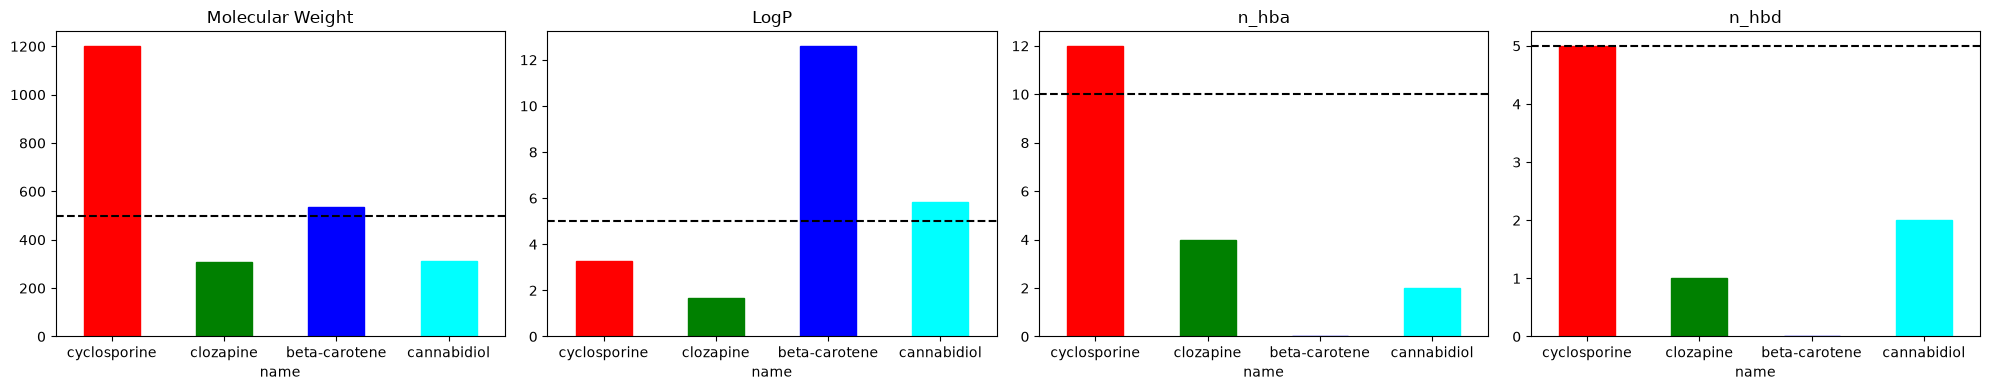

In [5]:
import matplotlib.pyplot as plt

# 1. GRAPH: Add .flatten() to turn the multi-dimensional grid into a simple list
axes = molecules.plot(
    kind = "bar", 
    x = "name", 
    y = ["molecular_weight", "logp", "n_hba", "n_hbd"], 
    subplots = True, 
    layout = (1, 4), 
    figsize=(20, 4),
    rot = 0,
    legend = False # Hides the default legend to keep it clean
).flatten()  # <-- This is the magic fix!

# 2. COLOR: Loop through each subplot and color the individual bars
for ax in axes:
    # ax.containers[0] holds the individual bars in the chart
    # zip pairs each bar up with its matching color from your 'color' column
    for bar, color in zip(ax.containers[0], molecules["color"]):
        bar.set_color(color)

# 3. THRESHOLDS: Now axes[0] and axes[1] are direct individual charts
axes[0].axhline(y = 500, color = "black", linestyle = "dashed", label = "MW Limit")
axes[0].set_title("Molecular Weight")

# Add threshold to the second plot, and so on.
axes[1].axhline(y = 5, color = "black", linestyle="dashed", label="LogP Limit")
axes[1].set_title("LogP")

axes[2].axhline(y = 10, color = "black", linestyle = "dashed", label = "n_hba Limit")
axes[2].set_title("n_hba")

axes[3].axhline(y = 5, color = "black", linestyle = "dashed", label = "n_hbd Limit")
axes[3].set_title("n_hbd")

plt.tight_layout()
plt.show()

In [7]:
def calculate_ro5_properties(molecules):
    for index, row in molecules.iterrows():
        # This defines 'molecule' from your SMILES column so RDKit can read it
        molecule = Chem.MolFromSmiles(row["smiles"])
        
        molecular_weight = Descriptors.ExactMolWt(molecule)
        n_hba = Descriptors.NumHAcceptors(molecule)
        n_hbd = Descriptors.NumHDonors(molecule)
        logp = Descriptors.MolLogP(molecule)
        Ro5 = 0
        if molecular_weight <= 500:
            Ro5 += 1
        if n_hba <= 10:
            Ro5 += 1
        if n_hbd <= 5:
            Ro5 += 1
        if logp <= 5:
            Ro5 += 1
            
        if Ro5 >= 3:
            print(f"Ro5 fulfilled for {row['name']}: True")
        else:
            print(f"Ro5 fulfilled for {row['name']}: False")
calculate_ro5_properties(molecules)

Ro5 fulfilled for cyclosporine: False
Ro5 fulfilled for clozapine: True
Ro5 fulfilled for beta-carotene: False
Ro5 fulfilled for cannabidiol: True


In [10]:
molecules = pd.read_csv("EGFR_compounds.csv", index_col=0)
molecules.head()

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL304271,0.45,nM,CCN(CC)CC(O)CNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc...,9.346787
1,CHEMBL264382,1.10,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.958607
2,CHEMBL69358,1.20,nM,CCN(CC)CCNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4...,8.920819
3,CHEMBL67003,1.80,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,8.744727
4,CHEMBL305246,2.80,nM,Cc1cc(C(=O)N2CCN(C)CC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.552842


In [11]:
def calculate_ro5_properties(molecules):
    for index, row in molecules.iterrows():
        # This defines 'molecule' from your SMILES column so RDKit can read it
        molecule = Chem.MolFromSmiles(row["smiles"])
        
        molecular_weight = Descriptors.ExactMolWt(molecule)
        n_hba = Descriptors.NumHAcceptors(molecule)
        n_hbd = Descriptors.NumHDonors(molecule)
        logp = Descriptors.MolLogP(molecule)
        Ro5 = 0
        if molecular_weight <= 500:
            Ro5 += 1
        if n_hba <= 10:
            Ro5 += 1
        if n_hbd <= 5:
            Ro5 += 1
        if logp <= 5:
            Ro5 += 1
            
        if Ro5 >= 3:
            print(f"Ro5 fulfilled for {row['molecule_chembl_id']}: True")
        else:
            print(f"Ro5 fulfilled for {row['molecule_chembl_id']}: False")
calculate_ro5_properties(molecules)

Ro5 fulfilled for CHEMBL304271: True
Ro5 fulfilled for CHEMBL264382: True
Ro5 fulfilled for CHEMBL69358: True
Ro5 fulfilled for CHEMBL67003: True
Ro5 fulfilled for CHEMBL305246: True
Ro5 fulfilled for CHEMBL67057: True
Ro5 fulfilled for CHEMBL308645: True
Ro5 fulfilled for CHEMBL69071: True
Ro5 fulfilled for CHEMBL69629: True
Ro5 fulfilled for CHEMBL134312: True
Ro5 fulfilled for CHEMBL66570: True
Ro5 fulfilled for CHEMBL136491: True
Ro5 fulfilled for CHEMBL69966: True
Ro5 fulfilled for CHEMBL302552: True
Ro5 fulfilled for CHEMBL133023: True
Ro5 fulfilled for CHEMBL424093: True
Ro5 fulfilled for CHEMBL305194: True
Ro5 fulfilled for CHEMBL137534: True
Ro5 fulfilled for CHEMBL137617: True
Ro5 fulfilled for CHEMBL68920: True
Ro5 fulfilled for CHEMBL52765: True
Ro5 fulfilled for CHEMBL137364: True
Ro5 fulfilled for CHEMBL136674: True
Ro5 fulfilled for CHEMBL133024: True
Ro5 fulfilled for CHEMBL76589: True
Ro5 fulfilled for CHEMBL69960: True
Ro5 fulfilled for CHEMBL305782: True
Ro5 fulfille

In [12]:
results = []
for index, row in molecules.iterrows():
    molecule = Chem.MolFromSmiles(row["smiles"])
    mw = Descriptors.ExactMolWt(molecule)
    hba = Descriptors.NumHAcceptors(molecule)
    hbd = Descriptors.NumHDonors(molecule)
    logp = Descriptors.MolLogP(molecule)
    
    Ro5 = (mw <= 500) + (hba <= 10) + (hbd <= 5) + (logp <= 5)
    results.append({
        "molecular_weight": mw,
        "n_hba": hba,
        "n_hbd": hbd,
        "logp": logp,
        "ro5_fulfilled": Ro5 >= 3
    })

ro5_properties = pd.DataFrame(results)
ro5_properties.head()

,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,541.200444,7,5,3.57442,True
1,602.275387,7,4,4.41442,True
2,511.189879,6,4,4.21352,True
3,560.228437,7,3,4.21982,True
4,495.158579,6,3,3.52952,True


In [13]:
molecules = pd.concat([molecules, ro5_properties], axis=1)
molecules.head()

,molecule_chembl_id,IC50,units,smiles,pIC50,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,CHEMBL304271,0.45,nM,CCN(CC)CC(O)CNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc...,9.346787,541.200444,7,5,3.57442,True
1,CHEMBL264382,1.10,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.958607,602.275387,7,4,4.41442,True
2,CHEMBL69358,1.20,nM,CCN(CC)CCNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4...,8.920819,511.189879,6,4,4.21352,True
3,CHEMBL67003,1.80,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,8.744727,560.228437,7,3,4.21982,True
4,CHEMBL305246,2.80,nM,Cc1cc(C(=O)N2CCN(C)CC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.552842,495.158579,6,3,3.52952,True


In [15]:
# Note that the column "ro5_fulfilled" contains boolean values.
# Thus, we can use the column values directly to subset data.
# Note that ~ negates boolean values.
molecules_ro5_fulfilled = molecules[molecules["ro5_fulfilled"]]
molecules_ro5_violated = molecules[~molecules["ro5_fulfilled"]]

print(f"# compounds in unfiltered data set: {molecules.shape[0]}")
print(f"# compounds in filtered data set: {molecules_ro5_fulfilled.shape[0]}")
print(f"# compounds not compliant with the Ro5: {molecules_ro5_violated.shape[0]}")
# NBVAL_CHECK_OUTPUT

# compounds in unfiltered data set: 101
# compounds in filtered data set: 101
# compounds not compliant with the Ro5: 0


In [16]:
# Save filtered data
molecules_ro5_fulfilled.to_csv("EGFR_compounds_lipinski.csv")
molecules_ro5_fulfilled.head()

,molecule_chembl_id,IC50,units,smiles,pIC50,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,CHEMBL304271,0.45,nM,CCN(CC)CC(O)CNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc...,9.346787,541.200444,7,5,3.57442,True
1,CHEMBL264382,1.10,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.958607,602.275387,7,4,4.41442,True
2,CHEMBL69358,1.20,nM,CCN(CC)CCNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4...,8.920819,511.189879,6,4,4.21352,True
3,CHEMBL67003,1.80,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,8.744727,560.228437,7,3,4.21982,True
4,CHEMBL305246,2.80,nM,Cc1cc(C(=O)N2CCN(C)CC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.552842,495.158579,6,3,3.52952,True


In [26]:
def calculate_mean_std(dataframe):
    # Generate descriptive statistics for property columns
    stats = dataframe.describe()
    # Transpose DataFrame (statistical measures = columns)
    stats = stats.T
    # Select mean and standard deviation
    stats = stats[["mean", "std"]]
    return stats

In [18]:
molecules_ro5_fulfilled_stats = calculate_mean_std(
    molecules_ro5_fulfilled[["molecular_weight", "n_hba", "n_hbd", "logp"]]
)
molecules_ro5_fulfilled_stats
# NBVAL_CHECK_OUTPUT

,mean,std
molecular_weight,300.587440,126.015066
n_hba,4.673267,1.386426
n_hbd,2.108911,1.165341
logp,2.602822,1.459822


In [22]:
molecules_ro5_violated_stats = calculate_mean_std(
    molecules_ro5_violated[["molecular_weight", "n_hba", "n_hbd", "logp"]]
)
molecules_ro5_violated_stats

,mean,std
molecular_weight,NaN,NaN
n_hba,NaN,NaN
n_hbd,NaN,NaN
logp,NaN,NaN


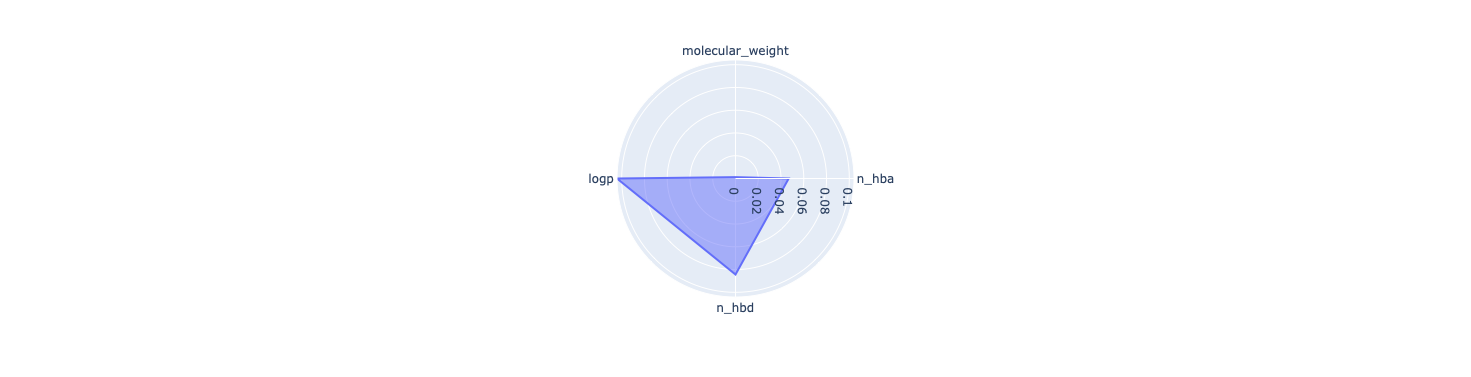

In [46]:
import plotly.express as px
import pandas as pd

# If your normalized stats are ready, just pass them in:
# Plotly automatically figures out the angles and layout for you
fig = px.line_polar(molecules_ro5_fulfilled_stats, r = 'mean', theta=molecules_ro5_fulfilled_stats.index, line_close=True) #draw the polygon
fig.update_traces(fill = 'toself') #make changes to polygon you drew with last line of code
fig.show()
